### TEAM Members: 

*Isabella Odom*  
*Nolan Bouchert*

# MET 3602 Hackathon Fall 2026

This problem can be solved by adding code to this notebook. There is 1 question worth 100 points.

You may use an AI engine, however <span style = "color:red">you will lose points</span> if you do not cite your sources - <u>you must include screen dumps</u>. 


Turn in a completed notebook, renamed as

`MET3602_Hack_Isabella_Nolan.ipynb`

in <u>both</u> JupyterHub and Canvas. 

**Hand in (upload to Canvas) at the end of class today, October 9 2026, at 12:00 p.m.**

Be sure to clean up and comment your code for each problem, and that your output is self-describing. Also, run all cells to ensure that the code executes! You can create additional boxes in order to test portions of the code. However, please comment these out before submitting the exam.

In [ ]:
from datetime import datetime, timedelta
import xarray as xr

import matplotlib.pyplot as plt
import metpy.calc as mpcalc
from metpy.units import units
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

## Question: In Thickness and in Health
  The depth of a layer between two isobaric surfaces is defined by the hypsometric equation, i.e.

\begin{equation}
\Delta z ={\frac{R_d * \overline T_v}{g}\left[ln\frac{p_0}{p_1}\right]},
\end{equation}


where $p_{0}$ (> $p_{1}$) is the reference pressure (typically 1000 hPa), $\overline{T_v}$ is the layer mean virtual temperature in Kelvin, $R_{d}$ is the dry gas constant (287 J $K^{-1}$ $kg^{-1}$) and `g` is gravity (9.81 $ms^{-2}$). 

The layer thickness is a useful forecast tool. It is typically taken over the 1000 hPa to 850 hPa or 1000 hPa to 500 hPa. Here were are going to apply it to the former. In addition, we are not going to use that formula directly, but rather take the difference between the 850 and 1000 hPa heights (graphical analysis and we are going to let the computer do all of the work!). 

<br>
For this problem, you are going to generate a <u>single</u> figure that includes the following 3 items:  
<br>

* 1000 hPa heights (meters)
* 850 hPa  heights (meters)
* Layer thickness (i.e., 850 hPa heights - 1000 hPa heights)


You will be pulling the GFS analysis (initialization only) from the [NCAR](https://tds.scigw.unidata.ucar.edu/thredds/catalog/idd/forecastModels.html) THREDDS server using the datetime.  **Pull the 00 UTC cycle**

### Helpful Lecture:  
- 13_xarray_data_reading_and_matplotlib_contouring.ipynb

In [1]:
#Import all libraries here

from datetime import datetime, timedelta
import xarray as xr

import matplotlib.pyplot as plt
import metpy.calc as mpcalc
from metpy.units import units
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

### 1. Pry the dataset open (4 pts)

In [ ]:
#4 pts
# Set the date/time of the GFS model run
#               YYYY  MM  D  HH
date = datetime(2026,10,8,00)

# # Remote access to GFS model output from UCAR 
ds = xr.open_dataset('https://thredds.ucar.edu/thredds/dodsC/grib'
                      f'/NCEP/GFS/Global_0p5deg_ana/GFS_Global_0p5deg_ana_{date:%Y%m%d_%H%M}.grib2')

# #Pop the data - it is global!


In [ ]:
# Slice data to be just over the U.S. for plotting purposes!
ds = ds.sel(lat=slice(70,10), lon=slice(360-150, 360-55))

### 2. Date/Time Formatting (6 pts)

In [ ]:
# 6 pts (2 pts each)
###################################################################
#Print the 4-digit year string

#Print the 3-character month

#Print the numeric month (i.e., 1-12)


### 3. Slice and Dice:  Chop Chop (6 pts)

In [ ]:
#Now slice (select) the level and time from the subdomain for the following two levels.
#Use the .sel command to select the 'date', isobaric level and variable (Geopotential Height) 
#Select 1000 hPa. 

#Fill in the pressure level below. 3 pts
ds0 = ds.sel(time=date, isobaric = ?).(add variable name)

#Select 850 hPa.   3 pts
ds1 = ds.sel(time=date, isobaric = ?).(add variable name)

### 4. Let the thickness begin! (12 pts)

In [ ]:
# Calculate the layer 1000-to-850 layer thickness (this is just one line of code!) 
# and store it in an array named 'thick'.  6 pts


In [ ]:
#6 pts
#Pop the thickness array (see Xarray lecture

#Pop the latitude

#Print the shape of the thickness array


### 5. Generate Figures and Accessorize:  Cartopy at Work (72 pts)

In [ ]:
#Generate figure here

#1. Set Lambert Conformal projection (CONUS)   1 pt
mapcrs = ccrs.LambertConformal( ? )


#########################
#2. Set figure size and axis information (create an axis object, i.e. ax =...). set the CRS argument to
#   ccrs.PlateCarree()  5 pts



#########################
#3. #Set 'extent' to eastern 1/3 of the US (use the '.set_exent' method) 3 pts



#########################
#4. Apply 3 passes of a 9-pt smoother to the 850-to-1000 hPa thickness.   3 pts
#See https://unidata.github.io/MetPy/latest/api/generated/metpy.calc.smooth_n_point.html



#########################
#5. Add Contours of 850-to-1000 hPa thickness. If the thickness is >= 1300, use a solid contour. If it is < 1300 used
# dashed contours. This requires two separate calls to the contouring. See Xarray lecture. +10 pts



#########################
#6. Why am I asking you to separate (break) the contouring at 1300 m?      5 pts
#
#First, write a simple definition to calculate the mean layer temperature with
#inputs: thickness, p0, p1. The constants should be included in the function! What 
#temperature does it return when you set thickness = 1300 m? Put the function and the
#calculation at the end of the notebook (last cell).
#
#Brief answer:
#
#

#########################
#7. Apply 3 passes of a 9-point smoother to the 1000 hPa heights.         3 pts      
#See https://unidata.github.io/MetPy/latest/api/generated/metpy.calc.smooth_n_point.html



#########################
#8. Add the smoothed 1000 hPa contours to the figure (solid blue).        4 pts



#########################
#9. Apply 3 passes of a 9-point smoother to the 850 hPa heights 3 pts
#See https://unidata.github.io/MetPy/latest/api/generated/metpy.calc.smooth_n_point.html


#########################
#10. Add the smoothed 850 hPa contours to the figure.        4 pts



#########################
#11. Add Features: COASTLINE and STATES (see Cartopy)        3 pts



#########################
#12. Add Contour Labels (there should be 4 separate calls to the clabel method (one each for 1000 hPa, 850 hPa, thickness< 1300, 
#, and thickness >=1300). See Xarray lecture. 10 pts



#########################
#13. Add title and date information (do not hardwire the date - use the datetime string!)  5 pts



#########################
#14. Add lat/lon 'gridlines' with labels 5 pt  (e.g., https://cartopy.readthedocs.io/stable/matplotlib/gridliner.html)



#########################
#15. Add the following text: '850-1000' thickness, '1000 hPa heights', '850 hPa heights')  6 pts



#########################
#16. Save your figure: '850-1000_thick_Isabella_Nolan.png'   2 pts




### DRL's Figure!

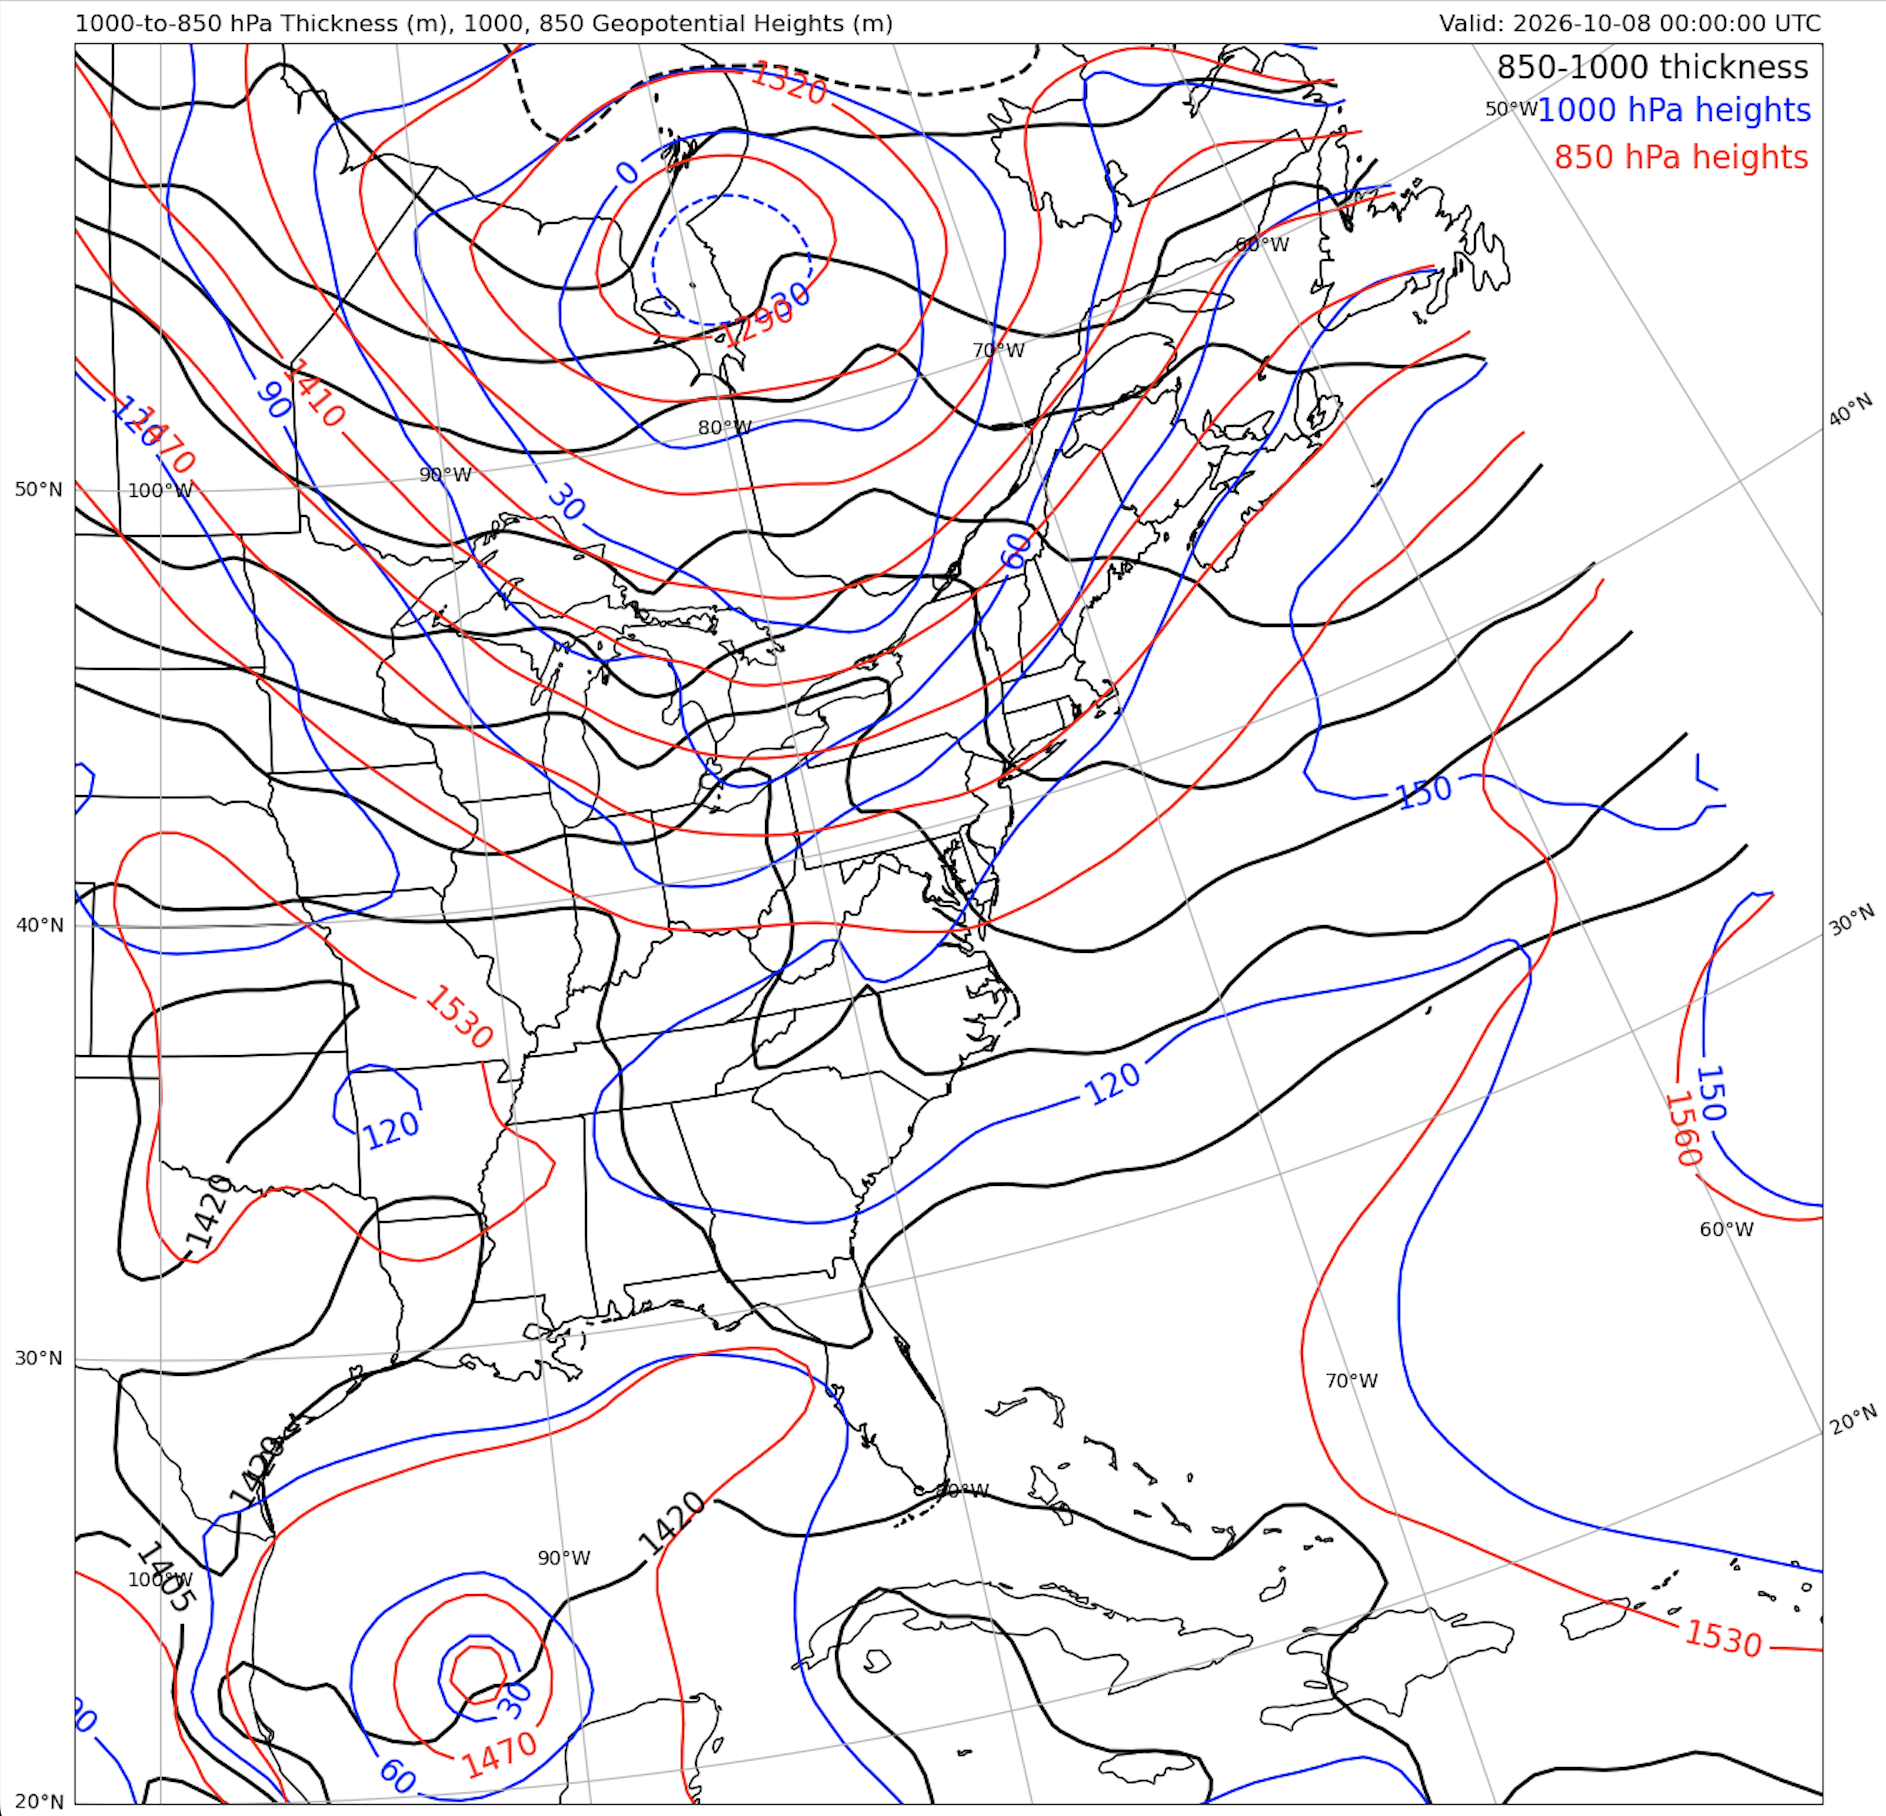